# Lab 16.4: Attribution Patching versus Real Patching

Run-only notebook for Chapter 16. Attribution patching estimates every patching effect from two forward passes and one backward pass. Here you compare it with exact patching for all 144 heads, then for the residual stream, where the approximation is expected to be worse.

In [1]:
import os, random, time
import numpy as np, torch, matplotlib
import matplotlib.pyplot as plt
from transformer_lens import HookedTransformer
torch.set_grad_enabled(False)
torch.manual_seed(0)
from importlib.metadata import version
print("torch", torch.__version__, "| transformer-lens", version("transformer-lens"), "| numpy", np.__version__)
t0 = time.time()
model = HookedTransformer.from_pretrained("gpt2", device="cpu")   # GPT-2 small, 124M parameters
print(f"loaded in {time.time() - t0:.0f} s")

torch 2.6.0 | transformer-lens 2.18.0 | numpy 1.26.4


Loaded pretrained model gpt2 into HookedTransformer
loaded in 1 s


In [2]:
NAMES = ["Mary", "John", "Alice", "Bob", "Sarah", "James", "Emma", "David",
         "Laura", "Michael", "Anna", "Daniel", "Maria", "Thomas", "Julia", "Peter"]
PLACES = ["store", "park", "office", "school", "beach", "market", "station", "garden"]
OBJS = ["drink", "ball", "book", "gift", "key", "letter", "ring", "bag"]
TPL = "When {A} and {B} went to the {P}, {B} gave a {O} to"
ROLES = ["BOS", "When", "IO", "and", "S1", "went", "to", "the", "place", ",", "S2", "gave", "a", "object", "END"]

rng = random.Random(0)
clean, corr, io, s = [], [], [], []
for _ in range(48):
    A, B = rng.sample(NAMES, 2); P = rng.choice(PLACES); O = rng.choice(OBJS)
    clean.append(TPL.format(A=A, B=B, P=P, O=O))
    corr.append(TPL.replace("{B} gave", "{A} gave").format(A=A, B=B, P=P, O=O))   # S2 becomes the IO name
    io.append(model.to_single_token(" " + A)); s.append(model.to_single_token(" " + B))
rng2 = random.Random(1)
abc = []
for i in range(48):                       # ABC corruption: same IO and S1, a third name at S2
    A, B = model.to_string(io[i]).strip(), model.to_string(s[i]).strip()
    C = rng2.choice([n for n in NAMES if n not in (A, B)])
    abc.append(clean[i].replace(f", {B} gave", f", {C} gave"))
clean_t, corr_t, abc_t = model.to_tokens(clean), model.to_tokens(corr), model.to_tokens(abc)
io, s = torch.tensor(io), torch.tensor(s)
N, T = clean_t.shape
assert corr_t.shape == clean_t.shape == abc_t.shape, "every prompt must have the same token length"

def logit_diff(logits):
    last = logits[:, -1]
    return last[range(N), io] - last[range(N), s]

clean_logits, clean_cache = model.run_with_cache(clean_t)
corr_logits, corr_cache = model.run_with_cache(corr_t)
abc_logits, abc_cache = model.run_with_cache(abc_t)
LD_clean = logit_diff(clean_logits).mean().item()
LD_corr = logit_diff(corr_logits).mean().item()
LD_abc = logit_diff(abc_logits).mean().item()
print(clean[0]); print(corr[0]); print(abc[0])
print(f"logit difference (IO minus S): clean {LD_clean:.2f}, corrupted {LD_corr:.2f}, ABC {LD_abc:.2f}")
print(f"clean prompts answered correctly: {(logit_diff(clean_logits) > 0).float().mean().item():.0%}")

When Maria and Peter went to the station, Peter gave a drink to
When Maria and Peter went to the station, Maria gave a drink to
When Maria and Peter went to the station, Alice gave a drink to
logit difference (IO minus S): clean 3.74, corrupted -3.88, ABC 0.96
clean prompts answered correctly: 100%


In [3]:
def restored(ld):
    return (ld - LD_corr) / (LD_clean - LD_corr)

# exact head patching (denoising), one run per head
t0 = time.time()
exact = np.zeros((12, 12))
for layer in range(12):
    for h in range(12):
        def hook(act, hook, h=h):
            act[:, :, h] = clean_cache[hook.name][:, :, h]
            return act
        out = model.run_with_hooks(corr_t, fwd_hooks=[(f"blocks.{layer}.attn.hook_z", hook)])
        exact[layer, h] = restored(logit_diff(out).mean().item())
print(f"exact patching: 144 runs in {time.time() - t0:.0f} s")

exact patching: 144 runs in 52 s


attribution patching: one backward pass in 1.1 s
correlation over 144 heads: 0.983
head 9.9: exact +0.27  attribution +0.40
head 8.6: exact +0.34  attribution +0.42
head 5.5: exact +0.35  attribution +0.29
head 3.0: exact +0.15  attribution +0.12
head 10.7: exact -0.50  attribution -0.47


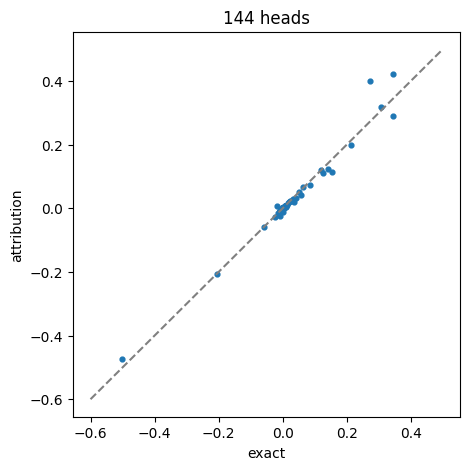

In [4]:
# attribution patching: gradient of the metric at the corrupted run, times (clean - corrupted)
t0 = time.time()
torch.set_grad_enabled(True)
acts, grads = {}, {}
keep = lambda n: n.endswith("hook_z") or n.endswith("hook_resid_pre")
def fwd(act, hook): acts[hook.name] = act.detach(); return act
def bwd(grad, hook): grads[hook.name] = grad.detach()
model.reset_hooks(); model.add_hook(keep, fwd, "fwd"); model.add_hook(keep, bwd, "bwd")
metric = restored(logit_diff(model(corr_t)).mean())
metric.backward()
model.reset_hooks(); torch.set_grad_enabled(False)
approx = np.zeros((12, 12))
for layer in range(12):
    n = f"blocks.{layer}.attn.hook_z"
    approx[layer] = ((clean_cache[n] - acts[n]) * grads[n]).sum((0, 1, 3)).numpy()
print(f"attribution patching: one backward pass in {time.time() - t0:.1f} s")
r = np.corrcoef(exact.ravel(), approx.ravel())[0, 1]
print(f"correlation over 144 heads: {r:.3f}")
gap = np.argsort(-np.abs(approx - exact).ravel())[:5]
for i in gap:
    print(f"head {i // 12}.{i % 12}: exact {exact.ravel()[i]:+.2f}  attribution {approx.ravel()[i]:+.2f}")
plt.figure(figsize=(5, 5)); plt.scatter(exact.ravel(), approx.ravel(), s=12)
plt.plot([-0.6, 0.5], [-0.6, 0.5], "--", color="gray"); plt.xlabel("exact"); plt.ylabel("attribution")
plt.title("144 heads"); plt.show()

**Checkpoint 1:** correlation about 0.98; the largest gaps are 9.9 (exact about 0.27, estimate about 0.40), 8.6, 5.5 and 3.0.

## Where the tangent line fails: the residual stream

Patching a whole residual stream vector is a large change. Compare exact patching with the attribution estimate at the S2 and final positions for every layer.

In [5]:
rows = []
for layer in range(12):
    n = f"blocks.{layer}.hook_resid_pre"
    for pos, role in [(10, "S2"), (14, "END")]:
        def hook(act, hook, pos=pos):
            act[:, pos] = clean_cache[hook.name][:, pos]
            return act
        ex = restored(logit_diff(model.run_with_hooks(corr_t, fwd_hooks=[(n, hook)])).mean().item())
        ap = ((clean_cache[n][:, pos] - acts[n][:, pos]) * grads[n][:, pos]).sum().item()
        rows.append((layer, role, ex, ap))
print("layer  position  exact   attribution")
for layer, role, ex, ap in rows:
    print(f"{layer:5d}  {role:8s}  {ex:+.2f}   {ap:+.2f}")

layer  position  exact   attribution
    0  S2        +1.00   +0.03
    0  END       +0.00   +0.00
    1  S2        +1.00   +0.13
    1  END       -0.00   -0.00
    2  S2        +1.00   +0.21
    2  END       -0.00   -0.00
    3  S2        +1.00   +0.24
    3  END       -0.00   -0.00
    4  S2        +1.00   +0.30
    4  END       -0.00   -0.00
    5  S2        +0.98   +0.55
    5  END       -0.00   -0.00
    6  S2        +0.98   +0.84
    6  END       +0.00   -0.00
    7  S2        +0.96   +0.67
    7  END       +0.02   +0.02
    8  S2        +0.75   +0.39
    8  END       +0.35   +0.32
    9  S2        +0.11   -0.07
    9  END       +0.98   +0.89
   10  S2        +0.01   -0.11
   10  END       +1.03   +1.26
   11  S2        +0.02   -0.06
   11  END       +0.99   +1.01


**Checkpoint 2:** at the final position in late layers, the estimate is close to the exact value; at S2 in early layers, where the exact value is about 1, the estimate is far off. Large patches and early layers are where Nanda (2023) and Kramar et al. (2024) expect the approximation to fail.

## Questions

1. Write a one-paragraph rule for a team: when may they rely on attribution patching alone, and when must they confirm with exact patching?
2. The correlation over heads is high. Why is a high correlation not enough to trust the estimate for any single head?
3. How much faster was attribution patching than exact patching here, and how would the gap grow for a model with 32 layers and 32 heads per layer?